# Problem 1: torus generation

A single Flow Matching model generates points on a torus with R=3 and r=1.
The target is uniform by surface area. We compare unconstrained, soft,
repeated-projection, and terminal-projection sampling.

In [1]:
from pathlib import Path
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")  # 小型网络用 CPU，方便复现
R, r = 3.0, 1.0
N_TRAIN, N_EVAL = 20000, 4000
TRAIN_STEPS, BATCH_SIZE = 6000, 512
ODE_STEPS, SOFT_STRENGTH = 100, 5.0
TOL = 0.01  # 几何距离单位；等于小半径的 1%
OUT = Path("results/problem1")
OUT.mkdir(parents=True, exist_ok=True)
Path("models").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)
print(f"PyTorch {torch.__version__}; device={DEVICE}; seed={SEED}")

PyTorch 2.14.1; device=cpu; seed=42


## 1. Surface-area sampling

The torus is parameterized by

$$
x=(R+r\cos\phi)\cos\theta,\quad y=(R+r\cos\phi)\sin\theta,\quad z=r\sin\phi.
$$

Here $\theta$ runs around the main ring and $\phi$ around the tube. The area element
is $r(R+r\cos\phi)d\theta d\phi$, so uniform surface-area sampling requires

$$
p(\theta)=1/(2\pi),\qquad p(\phi)=\frac{R+r\cos\phi}{2\pi R}.
$$

The outer side has more area per angular interval. We propose $\phi$ uniformly and
accept it with probability $(R+r\cos\phi)/(R+r)$. Training and reference samples
use independent seeds.

In [2]:
def sample_torus(n, seed):
    rng = np.random.default_rng(seed)
    accepted = []
    count = 0
    while count < n:
        proposal = rng.uniform(-np.pi, np.pi, 2 * (n - count))
        keep = rng.random(len(proposal)) < (R + r * np.cos(proposal)) / (R + r)
        values = proposal[keep]
        accepted.append(values)
        count += len(values)
    phi = np.concatenate(accepted)[:n]
    theta = rng.uniform(-np.pi, np.pi, n)
    x = np.column_stack(((R + r*np.cos(phi))*np.cos(theta),
                         (R + r*np.cos(phi))*np.sin(theta), r*np.sin(phi)))
    return torch.tensor(x, dtype=torch.float32)

train_data = sample_torus(N_TRAIN, SEED)
reference = sample_torus(N_EVAL, 1001)
reference2 = sample_torus(N_EVAL, 1002)
np.save("data/torus_train.npy", train_data.numpy())
np.save("data/torus_reference.npy", reference.numpy())
print("Training:", train_data.shape, "Independent reference:", reference.shape)

Training: torch.Size([20000, 3]) Independent reference: torch.Size([4000, 3])


## 2. Constraint and projection

Let $\rho=\sqrt{x^2+y^2}$ and $q=\sqrt{(\rho-R)^2+z^2}$. The surface constraint is
$q=r$, and the Euclidean distance to the surface is $d=|q-r|$.

Projection finds the nearest ring center $c=(Rx/\rho,Ry/\rho,0)$ and scales the
offset from it to length $r$. On the central axis the center is not unique; on the
tube centerline the direction is not unique. The implementation chooses +x and
the outward direction, respectively, to avoid division by zero.

In [3]:
def torus_distance(x):
    rho = torch.linalg.vector_norm(x[:, :2], dim=1)
    q = torch.sqrt((rho - R)**2 + x[:, 2]**2)
    return (q - r).abs()


def project_torus(x):
    rho = torch.linalg.vector_norm(x[:, :2], dim=1, keepdim=True)
    direction = x[:, :2] / rho.clamp_min(1e-12)
    fallback = torch.zeros_like(direction)
    fallback[:, 0] = 1.0
    direction = torch.where(rho > 1e-12, direction, fallback)
    center = torch.cat((R * direction, torch.zeros_like(rho)), dim=1)
    offset = x - center
    length = torch.linalg.vector_norm(offset, dim=1, keepdim=True)
    outward = torch.cat((direction, torch.zeros_like(rho)), dim=1)
    unit = torch.where(length > 1e-12, offset / length.clamp_min(1e-12), outward)
    return center + r * unit

# 几何检查：特殊点、随机点、幂等性、距离等于投影位移
probe = torch.cat((torch.randn(1000, 3)*4,
                   torch.tensor([[0.,0.,0.], [0.,0.,2.], [R,0.,0.]])))
projected = project_torus(probe)
assert torch.isfinite(projected).all()
assert torus_distance(projected).max() < 2e-6
assert torch.allclose(project_torus(projected), projected, atol=2e-6)
assert torch.allclose(torch.linalg.vector_norm(probe-projected, dim=1),
                      torus_distance(probe), atol=2e-6)
assert torus_distance(train_data).max() < 2e-6
print("Geometry checks passed.")

Geometry checks passed.


## 3. Flow Matching

Sample independent $x_0\sim N(0,I)$, a training point $x_1$, and $t\sim U(0,1)$:

$$
x_t=(1-t)x_0+t x_1,\quad u=x_1-x_0,
\quad L=\mathbb{E}\|v_\theta(x_t,t)-u\|^2.
$$

The MLP takes three coordinates and time, and predicts three velocity components.
Training uses no projection or constraint loss. The four methods share the model
and differ only at sampling time. Individual target velocities are noisy, so
training loss need not approach zero.

Reference: [Flow Matching for Generative Modeling](https://arxiv.org/abs/2210.02747).
This implementation interpolates between independently sampled endpoints.

Step  1000: mean recent loss=2.6342
Step  2000: mean recent loss=2.6017
Step  3000: mean recent loss=2.5641
Step  4000: mean recent loss=2.5454
Step  5000: mean recent loss=2.5516
Step  6000: mean recent loss=2.5404
Training time: 5.2 seconds


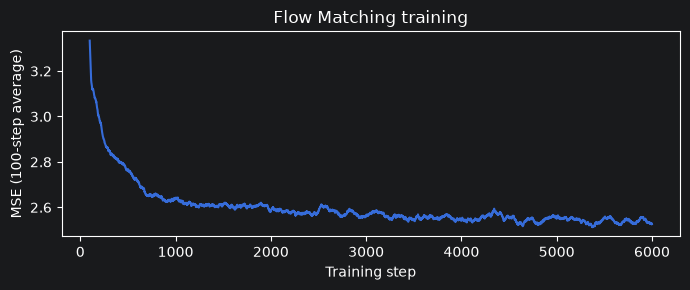

In [10]:
class VelocityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, 128), nn.SiLU(),
                                 nn.Linear(128, 128), nn.SiLU(),
                                 nn.Linear(128, 128), nn.SiLU(),
                                 nn.Linear(128, 3))

    def forward(self, x, t):
        return self.net(torch.cat((x, t), dim=1))

torch.manual_seed(SEED)
model = VelocityNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
losses = []
start = time.perf_counter()
for step in range(TRAIN_STEPS):
    idx = torch.randint(N_TRAIN, (BATCH_SIZE,))
    x1 = train_data[idx].to(DEVICE)
    x0 = torch.randn_like(x1)
    t = torch.rand(BATCH_SIZE, 1, device=DEVICE)
    xt = (1-t)*x0 + t*x1
    loss = ((model(xt, t) - (x1-x0))**2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (step+1) % 1000 == 0:
        print(f"Step {step+1:5d}: mean recent loss={np.mean(losses[-200:]):.4f}")
model.eval()
print(f"Training time: {time.perf_counter()-start:.1f} seconds")
torch.save({"state_dict": model.state_dict(), "R": R, "r": r,
            "seed": SEED, "steps": TRAIN_STEPS}, "models/torus_flow_matching.pt")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(pd.Series(losses).rolling(100).mean())
ax.set(xlabel="Training step", ylabel="MSE (100-step average)", title="Flow Matching training")
fig.tight_layout(); fig.savefig(OUT / "training.png", dpi=150); plt.show()

## 4. Sampling methods

Use Euler updates $y=x+\Delta t\,v_\theta(x,t)$ with the same model, initial noise,
and step count:

- A: $x\leftarrow y$.
- B: $x\leftarrow y+\alpha(\Pi(y)-y)$, with $\alpha=1-e^{-\lambda\Delta t}$
  and default $\lambda=5$. Smaller steps give smaller per-step corrections.
- C: $x\leftarrow\Pi(y)$ after every step, without projecting the initial noise.
- D: follow A's trajectory, then project once at the end.

$\lambda$ controls the soft sampling correction, not the training loss.
Saved trajectories show how the corrections affect paths.

In [5]:
@torch.no_grad()
def generate(noise, method, steps=ODE_STEPS, strength=SOFT_STRENGTH):
    x = noise.clone().to(DEVICE)
    dt = 1.0 / steps
    alpha = 1 - np.exp(-strength * dt)
    path = [x[:20].cpu().numpy().copy()]
    for k in range(steps):
        t = torch.full((len(x), 1), k*dt, device=DEVICE)
        y = x + dt * model(x, t)
        if method == "B Soft":
            x = y + alpha * (project_torus(y)-y)
        elif method == "C Repeated hard":
            x = project_torus(y)
        else:
            x = y
        path.append(x[:20].cpu().numpy().copy())
    if method == "D Terminal":
        x = project_torus(x)
        path.append(x[:20].cpu().numpy().copy())
    return x.cpu(), np.stack(path)

METHODS = ["A Unconstrained", "B Soft", "C Repeated hard", "D Terminal"]
generator = torch.Generator().manual_seed(2001)
noise = torch.randn(N_EVAL, 3, generator=generator)
samples, paths = {}, {}
for method in METHODS:
    samples[method], paths[method] = generate(noise, method)
assert torch.allclose(samples["D Terminal"], project_torus(samples["A Unconstrained"]), atol=1e-6)
for method in ["C Repeated hard", "D Terminal"]:
    assert torus_distance(samples[method]).max() < 2e-6
np.savez(OUT / "samples.npz", **{key: value.numpy() for key, value in samples.items()})
print("Four methods generated from identical noise; terminal equivalence verified.")

Four methods generated from identical noise; terminal equivalence verified.


## 5. Evaluation

Feasibility reports mean, P95, and maximum surface distance, plus the fraction
with $d\le0.01$. Maximum projection residuals also check the hard methods.

Fidelity uses:

1. 3D sliced Wasserstein-1: project onto 128 fixed random directions, sort, and
   average absolute differences. It responds to geometry and density errors.
2. Angular joint TV: extract $(\theta,\phi)$ with atan2 and compare a 12 x 12
   histogram to the analytical surface-area target.
   $TV=\frac{1}{2}\sum|p-q|$. For off-surface points, angles describe the nearest
   surface direction; this metric does not replace feasibility.
3. Reference comparisons: SWD between independent real samples and the real
   sample's angular TV provide a baseline for finite-sample error.

Lower SWD and TV indicate closer distributions. Periodic angle boundaries are
consistent across comparisons. Binning, sample count, and projection count affect
the metrics, so plots and sampling replicates accompany them.

In [6]:
def angles(x):
    a = x.numpy() if isinstance(x, torch.Tensor) else np.asarray(x)
    theta = np.arctan2(a[:, 1], a[:, 0])
    phi = np.arctan2(a[:, 2], np.linalg.norm(a[:, :2], axis=1)-R)
    return theta, phi

BINS = 12
edges = np.linspace(-np.pi, np.pi, BINS+1)
phi_mass = (np.diff(edges) + (r/R)*np.diff(np.sin(edges))) / (2*np.pi)
expected_joint = np.outer(np.ones(BINS)/BINS, phi_mass)
rng = np.random.default_rng(3001)
directions = rng.normal(size=(128, 3))
directions /= np.linalg.norm(directions, axis=1, keepdims=True)

def joint_hist(x):
    theta, phi = angles(x)
    return np.histogram2d(theta, phi, bins=[edges, edges])[0] / len(x)

def swd(x, target):
    a, b = np.asarray(x), np.asarray(target)
    assert len(a) == len(b), "This simple estimator uses equal sample sizes."
    return np.abs(np.sort(a @ directions.T, axis=0) -
                  np.sort(b @ directions.T, axis=0)).mean()

def evaluate(x, target):
    d = torus_distance(x).numpy()
    return {"mean distance": d.mean(), "p95 distance": np.quantile(d, .95),
            "max distance": d.max(), "feasible fraction": (d <= TOL).mean(),
            "3D SWD": swd(x, target),
            "angular TV": 0.5*np.abs(joint_hist(x)-expected_joint).sum()}

rows = {"True reference": evaluate(reference2, reference)}
rows.update({key: evaluate(value, reference) for key, value in samples.items()})
metrics = pd.DataFrame(rows).T
metrics.to_csv(OUT / "metrics.csv")
display(metrics.round(5))
# 检验密度采样器，而不只是几何：E[cos(phi)]=r/(2R)
_, train_phi = angles(train_data)
assert abs(np.cos(train_phi).mean() - r/(2*R)) < .025
print("Target density check passed.")

,mean distance,p95 distance,max distance,feasible fraction,3D SWD,angular TV
True reference,0.00000,0.00000,0.00000,1.0000,0.05608,0.07730
A Unconstrained,0.04703,0.13394,1.79767,0.1745,0.07880,0.08554
B Soft,0.04833,0.10436,0.57597,0.0795,0.23286,0.62445
C Repeated hard,0.00000,0.00000,0.00000,1.0000,0.14722,0.47254
D Terminal,0.00000,0.00000,0.00000,1.0000,0.07743,0.08554


Target density check passed.


## 6. Plots

Point clouds compare real data and all four methods. Density plots show tube-angle
densities and joint-angle errors. Distance and path plots show constraint errors
and trajectories. Point clouds display the first 1,200 points; metrics use all
samples.

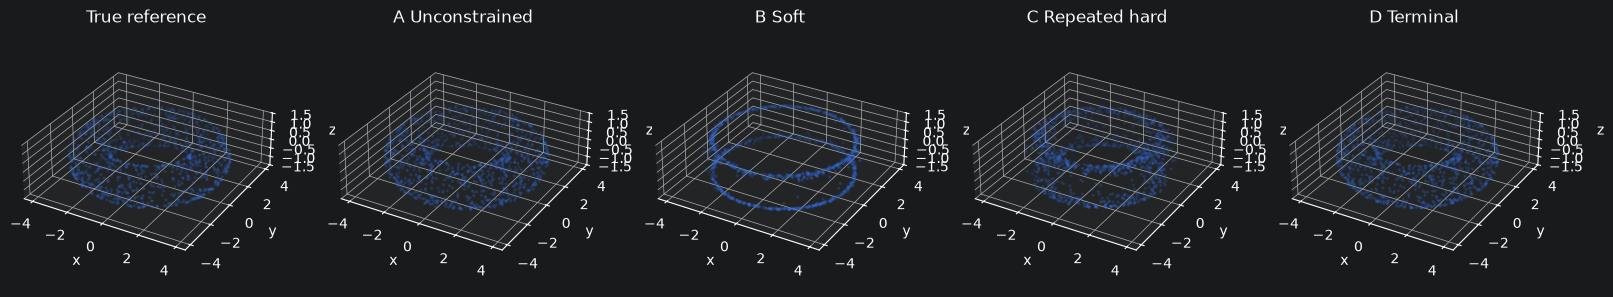

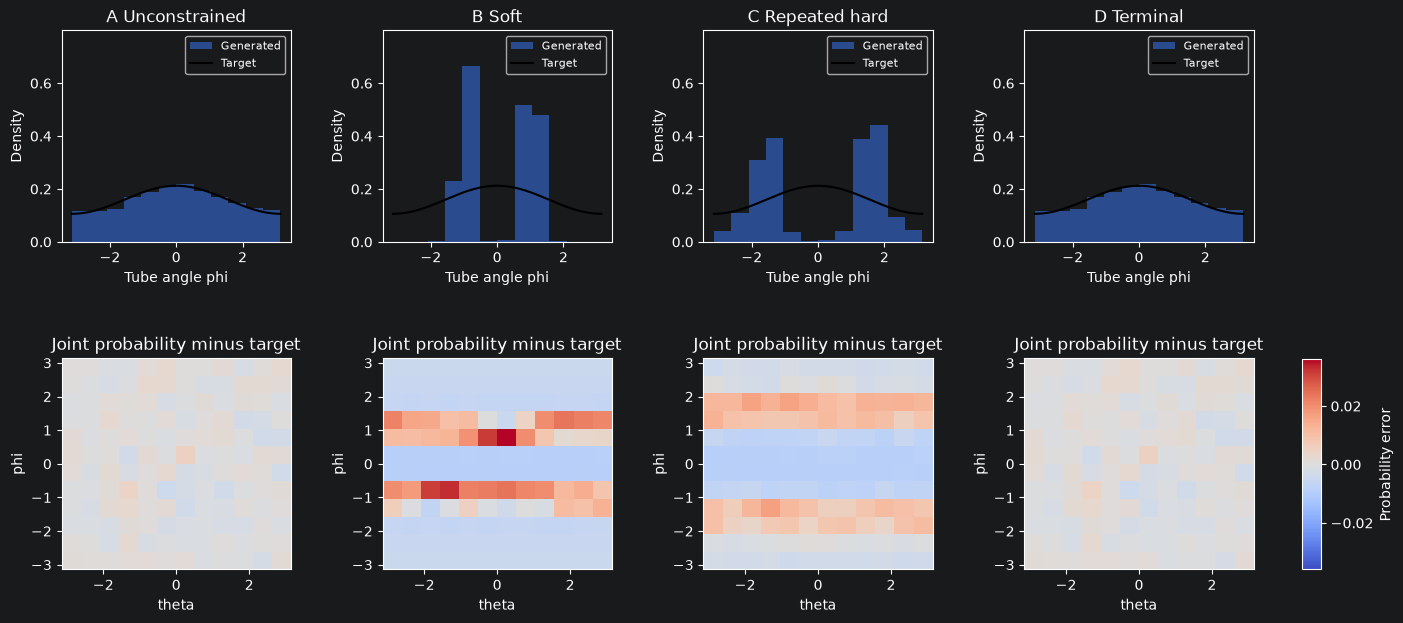

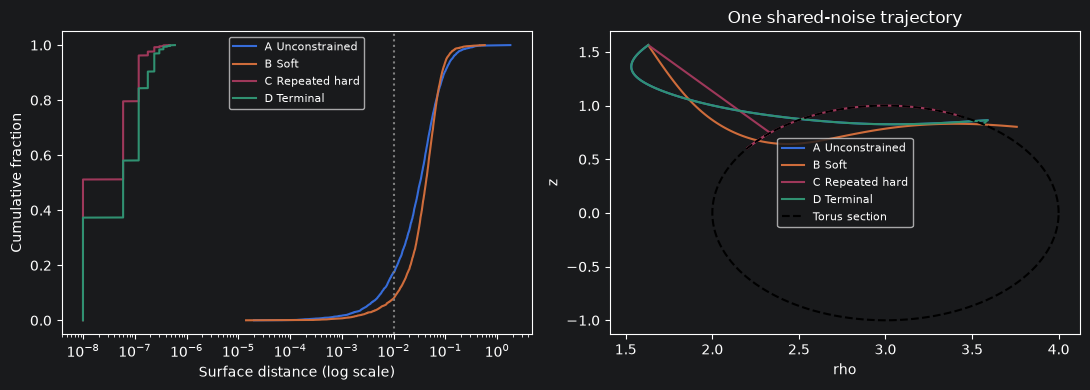

In [7]:
fig = plt.figure(figsize=(16, 3.5))
for i, (name, x) in enumerate({"True reference": reference, **samples}.items()):
    ax = fig.add_subplot(1, 5, i+1, projection="3d")
    a = x.numpy()[:1200]
    ax.scatter(*a.T, s=2, alpha=.45)
    ax.set(xlim=(-4.5,4.5), ylim=(-4.5,4.5), zlim=(-1.5,1.5),
           xlabel="x", ylabel="y", zlabel="z", title=name)
    ax.set_box_aspect((9,9,3))
fig.tight_layout(); fig.savefig(OUT / "point_clouds.png", dpi=160); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
max_density = max(np.histogram(angles(x)[1], bins=edges, density=True)[0].max() for x in samples.values())
vmax = max(np.abs(joint_hist(x)-expected_joint).max() for x in samples.values())
grid = np.linspace(-np.pi, np.pi, 300)
for j, (name, x) in enumerate(samples.items()):
    _, phi = angles(x)
    axes[0,j].hist(phi, bins=edges, density=True, alpha=.6, label="Generated")
    axes[0,j].plot(grid, (R+r*np.cos(grid))/(2*np.pi*R), color="black", label="Target")
    axes[0,j].set(title=name, xlabel="Tube angle phi", ylabel="Density", ylim=(0, max_density*1.2))
    axes[0,j].legend(fontsize=8)
    im = axes[1,j].imshow((joint_hist(x)-expected_joint).T, origin="lower",
                          extent=(-np.pi,np.pi,-np.pi,np.pi), cmap="coolwarm",
                          vmin=-vmax, vmax=vmax, aspect="auto")
    axes[1,j].set(xlabel="theta", ylabel="phi", title="Joint probability minus target")
fig.subplots_adjust(wspace=.4, hspace=.55, right=.87)
cax = fig.add_axes([.90, .11, .012, .30])
fig.colorbar(im, cax=cax, label="Probability error")
fig.savefig(OUT / "angular_fidelity.png", dpi=160); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, x in samples.items():
    d = np.sort(torus_distance(x).numpy())
    axes[0].plot(np.maximum(d, 1e-8), np.arange(1,len(d)+1)/len(d), label=name)
    p = paths[name][:,0,:]
    axes[1].plot(np.linalg.norm(p[:,:2], axis=1), p[:,2], label=name)
q = np.linspace(0,2*np.pi,300)
axes[1].plot(R+r*np.cos(q), r*np.sin(q), "k--", label="Torus section")
axes[0].axvline(TOL, color="gray", ls=":")
axes[0].set(xscale="log", xlabel="Surface distance (log scale)", ylabel="Cumulative fraction")
axes[1].set(xlabel="rho", ylabel="z", title="One shared-noise trajectory")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "feasibility_paths.png", dpi=160); plt.show()

## 7. Sampling variation and sensitivity

Keep the model fixed and repeat sampling with three independent noise seeds.
The reported standard deviations cover sampling variation, not retraining.
A separate sweep uses 1,000 shared noise points with soft strengths 0/1/5/20 and
Euler steps 50/100/200. These are diagnostic comparisons, not parameter selection
on the test set.

feasible fraction            3D SWD          angular TV  \
                             mean      std     mean      std       mean   
method                                                                    
A Unconstrained           0.16717  0.00376  0.05811  0.01062    0.08729   
B Soft                    0.08225  0.00225  0.22857  0.00284    0.62349   
C Repeated hard           1.00000  0.00000  0.14156  0.00843    0.47078   
D Terminal                1.00000  0.00000  0.05600  0.01021    0.08729   

                          
                     std  
method                    
A Unconstrained  0.00444  
B Soft           0.00378  
C Repeated hard  0.00543  
D Terminal       0.00444

,mean distance,p95 distance,max distance,feasible fraction,3D SWD,angular TV
setting,,,,,,
Soft lambda=0,0.04646,0.13952,0.35263,0.178,0.12465,0.13736
Soft lambda=1,0.04270,0.11624,0.61948,0.172,0.26693,0.36559
Soft lambda=5,0.05056,0.11441,0.53827,0.066,0.25978,0.62691
Soft lambda=20,0.02551,0.06268,0.11558,0.228,0.16925,0.50602
"A Unconstrained, steps=50",0.04671,0.14449,0.40561,0.171,0.12434,0.13774
"B Soft, steps=50",0.04698,0.10809,0.47923,0.088,0.25571,0.61484
"C Repeated hard, steps=50",0.00000,0.00000,0.00000,1.000,0.18992,0.47565
"D Terminal, steps=50",0.00000,0.00000,0.00000,1.000,0.12293,0.13774
"A Unconstrained, steps=100",0.04646,0.13952,0.35263,0.178,0.12465,0.13736


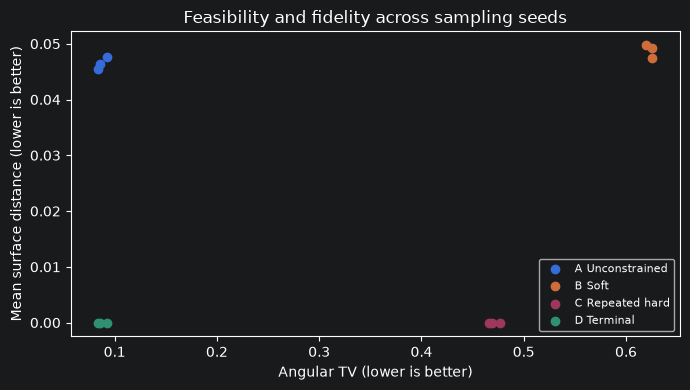

In [8]:
records = []
for seed in [2101, 2102, 2103]:
    z = torch.randn(N_EVAL, 3, generator=torch.Generator().manual_seed(seed))
    for name in METHODS:
        x, _ = generate(z, name)
        records.append({"seed": seed, "method": name, **evaluate(x, reference)})
replicates = pd.DataFrame(records)
replicates.to_csv(OUT / "sampling_replicates.csv", index=False)
display(replicates.groupby("method")[["feasible fraction", "3D SWD", "angular TV"]].agg(["mean", "std"]).round(5))

sensitivity = []
small_noise, small_ref = noise[:1000], reference[:1000]
for strength in [0., 1., 5., 20.]:
    x, _ = generate(small_noise, "B Soft", strength=strength)
    sensitivity.append({"setting": f"Soft lambda={strength:g}", **evaluate(x, small_ref)})
for steps in [50, 100, 200]:
    for name in METHODS:
        x, _ = generate(small_noise, name, steps=steps)
        sensitivity.append({"setting": f"{name}, steps={steps}", **evaluate(x, small_ref)})
sensitivity = pd.DataFrame(sensitivity).set_index("setting")
sensitivity.to_csv(OUT / "sensitivity.csv")
display(sensitivity.round(5))
fig, ax = plt.subplots(figsize=(7,4))
for name in METHODS:
    sub = replicates[replicates.method == name]
    ax.scatter(sub["angular TV"], sub["mean distance"], label=name)
ax.set(xlabel="Angular TV (lower is better)", ylabel="Mean surface distance (lower is better)",
       title="Feasibility and fidelity across sampling seeds")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(OUT / "tradeoff.png", dpi=160); plt.show()

## 8. Discussion

The output below reports this run's measured values. Both hard methods satisfy
the surface constraint to numerical precision, while their angular densities
can differ.

Intermediate training paths generally leave the torus. Repeated projection moves
states away from those paths before the model predicts the next velocity.
Terminal projection preserves the unconstrained path, but its final projection
does not guarantee the target density. Increasing soft strength need not improve
fidelity monotonically.

Only one model was trained. Euler discretization, model fitting, finite samples,
and histogram binning introduce errors. An exact manifold distribution is
singular; a finite network with finitely many unconstrained sampling steps
generally approximates the surface. These results do not establish a ranking
for other applications.

In [9]:
for name in METHODS:
    row = metrics.loc[name]
    print(f"{name}: feasible={row['feasible fraction']:.1%}, "
          f"mean distance={row['mean distance']:.6f}, "
          f"SWD={row['3D SWD']:.4f}, angular TV={row['angular TV']:.4f}")
c_tv = metrics.loc["C Repeated hard", "angular TV"]
d_tv = metrics.loc["D Terminal", "angular TV"]
print(f"Repeated minus terminal angular TV: {c_tv-d_tv:+.4f}")
print("Positive means terminal has lower angular TV in this run; negative means repeated does.")
config = dict(seed=SEED, R=R, r=r, target="uniform surface area", n_train=N_TRAIN,
              n_eval=N_EVAL, train_steps=TRAIN_STEPS, batch_size=BATCH_SIZE,
              ode_steps=ODE_STEPS, soft_strength=SOFT_STRENGTH, tolerance=TOL,
              torch_version=torch.__version__, numpy_version=np.__version__)
(OUT / "config.json").write_text(json.dumps(config, indent=2))
assert all(torch.isfinite(x).all() for x in samples.values())
assert np.isfinite(metrics.to_numpy()).all()
print("RUN_ALL_OK: training, four samplers, metrics, plots and sensitivity checks completed.")

A Unconstrained: feasible=17.4%, mean distance=0.047027, SWD=0.0788, angular TV=0.0855
B Soft: feasible=8.0%, mean distance=0.048330, SWD=0.2329, angular TV=0.6244
C Repeated hard: feasible=100.0%, mean distance=0.000000, SWD=0.1472, angular TV=0.4725
D Terminal: feasible=100.0%, mean distance=0.000000, SWD=0.0774, angular TV=0.0855
Repeated minus terminal angular TV: +0.3870
Positive means terminal has lower angular TV in this run; negative means repeated does.
RUN_ALL_OK: training, four samplers, metrics, plots and sensitivity checks completed.
